# AP 155 Lab Exercise
---
## Exercise 11: Montecarlo Methods

_Instructions_:
- **Report Figures**: 
 1. initial spin configuration, you choose  $T$
 2. spin configuration after 10,000 sweeps, for $T$ above and below $T_C$
 3. magnetization and energy, for $T$ above and below $T_C$
 4. magnetization and energy with external field, for $T$ above and below $T_C$
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Abellana, Gian
- _Student No._: 2024-09545
- _Section_: WX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

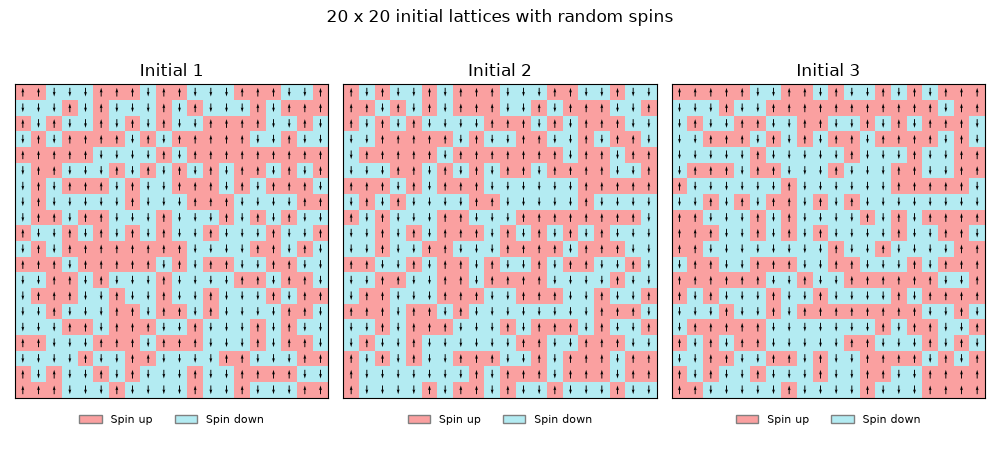

Figure 1. Initial 2D Ising models of size 20 x 20. Initialized with random up (+1) and down (-1) spins.

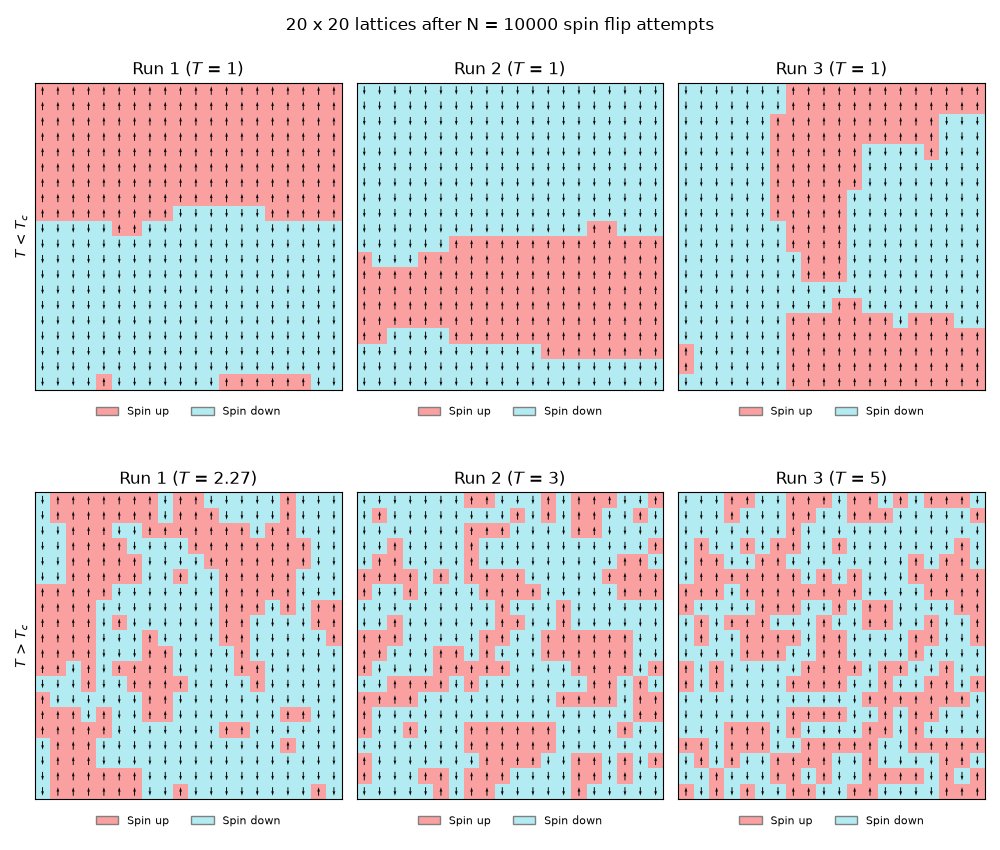

Figure 2. The spin configuration after N = 10000 sweeps. At $T = 1 < T_c$ and at $T = 2.27, 3, 5 \geq T_c$. Observe that for $T < T_c$, the model forms large patches of magnetic domains. For $T = T_c$, the patches become smaller but more frequent, and as $T > T_c$, the magnetic domain patches become even smaller and more frequent. As T becomes greater, the spin states become more random.

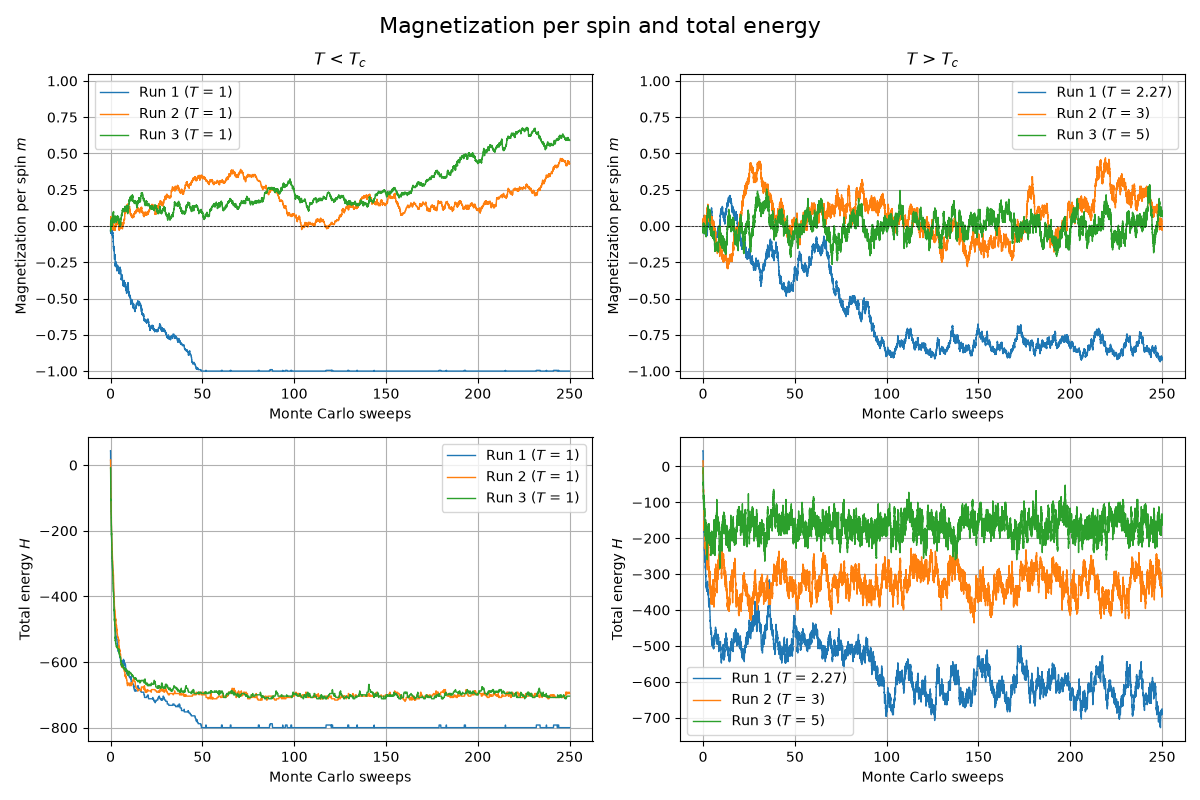

Figure 3. Magnetization and Energy for $T > T_c$ and $T < T_c$. Note that if $T < T_c$, the magnetization per spin is more smooth over the Monte Carlo sweeps and for $T \geq T_c$ it fluctuates way more. This is because the added temperature introduces energy which makes flipping a spin state more probable.

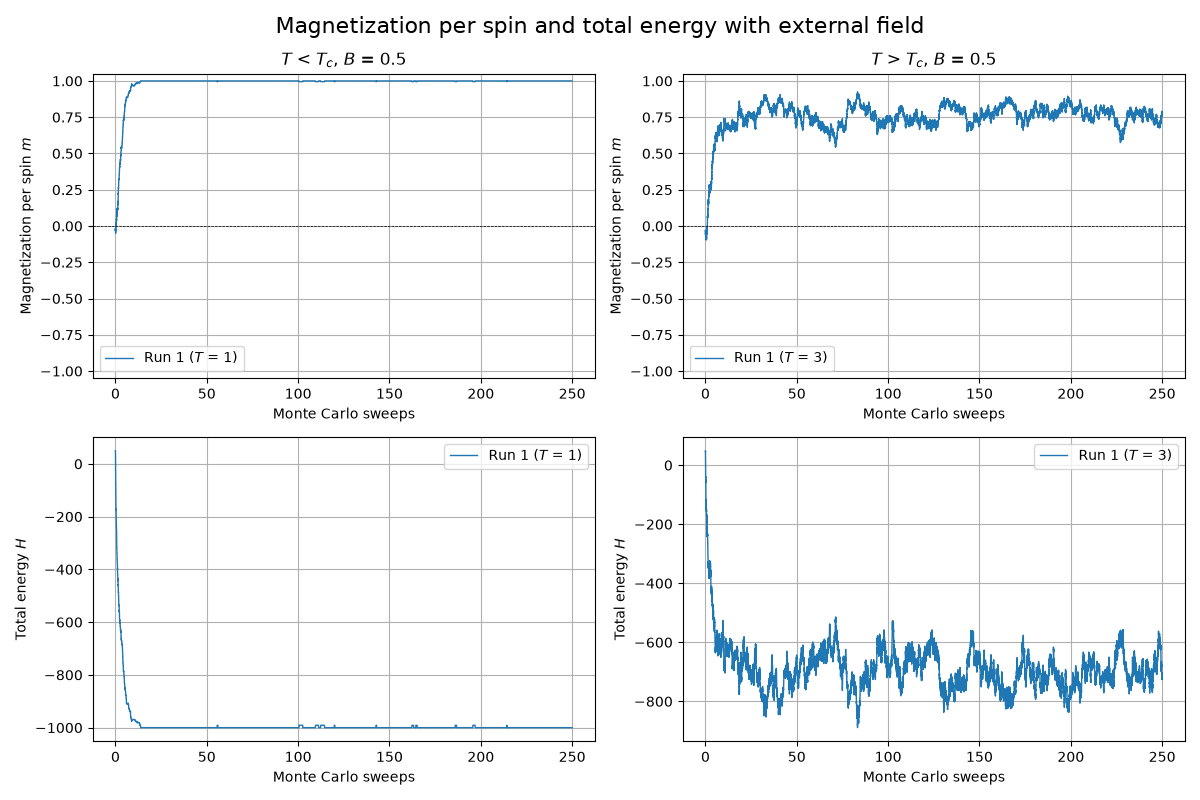

Figure 4. Magnetization and Energy with an external magnetic field $B = 0.5$, $T > T_c$ and $T < T_c$. We see the same dynamics as in Figure 2 with B = 0. However, we now see a trend towards aligning with the external magnetic field. This is because the magnetic field changes the potential in a way that spins aligning with the magnetic field provide lower energy, which is generally more stable.

### Report discussion

When creating a random 2D Ising model, it is expected that the initial magnetization is 0 since generating one is completely random with allowed spins -1,1 with equal probability. The total energy when completely aligned is $-2JN^2$ where N is the size of the model since there are $2N^2$ unique bonds. For N = 20 and J = 1, total energy is -800 \[J].

If the system temperature $T$ < $T_c$ where $T_c$ is the Curie point temperature for the 2D Ising model, it tends to spontaneously magnetize (Figure 2). Near $T_c$, it still seems to magnetize, but with magnetic domains of the opposite spin appears. Greatly above $T_c$, it no longer magnetizes as the number of magnetic domain patches increase. When there is no applied external magnetic field, the Hamiltonian is 'symmetric' ($H(\mathbf{S}) = H(-\mathbf{S})$ since $S_iS_j = (-S_i)(-S_j)$), so it could produce either positive or negative magnetization. Starting from a completely random 2D Ising model and no external magnetic field, there is no preferred spin orientation, the system could align to either from the random fluctuations as seen in. 

However the preferred spin orientation would be the direction of the external magnetic field $B$ if applied (Figure 4). This is because the external magnetic field changes the potential, such that the spin-aligned configurations achieve a lower energy, which is a more stable configuration. The system favors one magnetization direction over the other because it breaks the symmetry of the Hamiltonian talked about earlier. $B > 0$ would favor spin up alignment and $B < 0$ would favor spin down alignment.




---
## Section 2: Code

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# Exercise: The Two-Dimensional Ising Model

## Introduction

The Ising model describes the magnetic behavior of a material using interacting spins arranged on a lattice. Each spin can take one of two values, $S_{i,j}=\pm1$, representing spin-up and spin-down orientations.

In this exercise, you will simulate a two-dimensional Ising model using the **Metropolis Monte Carlo algorithm**. You will investigate how spin interactions, temperature, and external magnetic fields affect the system's energy and magnetization.

## 1. Setting Up the Ising Model

Consider a square lattice of size $N\times N$. Each spin interacts with its four nearest neighbors.

The energy of the system is given by the Ising Hamiltonian:

$$
H(\mathbf S)=-J\sum_{\langle ij\rangle}S_iS_j
$$

where $J$ is the interaction strength and the summation includes each unique neighboring pair exactly once.

Use **periodic boundary conditions**, where the lattice wraps around itself so that every spin has four neighbors.

**Tasks:**

1. Create a $20\times20$ lattice with randomly initialized spins of $+1$ or $-1$.
2. Plot the initial spin configuration.
3. Write a function to calculate the total energy using:

$$
H=-J\sum_{i,j}S_{i,j}(S_{i+1,j}+S_{i,j+1})
$$

**Guide questions:**
- What is the expected initial magnetization?
- What is the energy of a completely aligned lattice when $J>0$?

## 2. Implementing the Metropolis Algorithm

The probability of a spin configuration is proportional to its Boltzmann factor:

$$
w(\mathbf S)\propto e^{-H(\mathbf S)/(k_BT)}
$$

To simulate the system, randomly select and attempt to flip one spin at a time.

For each attempted flip:

1. Randomly select a spin $S_{i,j}$.
2. Flip its orientation: $S_{i,j}'=-S_{i,j}$.
3. Calculate the energy change:

$$
\Delta H=H_{\text{new}}-H_{\text{old}}
$$

4. Accept the flip with probability:

$$
P_{\text{accept}}=\min\left(1,e^{-\Delta H/(k_BT)}\right)
$$

Let $J = T = k_B = 1$. Test your simulation for 10,000 Monte Carlo sweeps. Note that one sweep will cover $N^2$ lattice sites.

## 3. Investigating Spontaneous Magnetization

The total magnetization measures the overall alignment of spins:

$$
M=\sum_{i,j}S_{i,j}
$$

Define the (average) magnetization per spin as:

$$
m=\frac{M}{N^2}
$$

Its value ranges from $-1$ to $+1$, with values near zero indicating an approximately balanced spin distribution.

**Tasks:**

1. Run the simulation for $10^4 - 10^6$ attempted spin flips, you decide what's appropriate.
2. Record the magnetization per spin and total energy throughout the simulation.
3. Plot magnetization per spin and total energy against Monte Carlo sweeps.
4. Repeat the simulation using different random initial configurations.

**Guide questions:**
- Does the system develop spontaneous magnetization?
- Why can separate simulations produce positive or negative magnetization?
- What determines the preferred spin orientation?

## 4. Introducing an External Magnetic Field

Modify the Hamiltonian to include a uniform external magnetic field:

$$
H(\mathbf S)=-J\sum_{\langle ij\rangle}S_iS_j-B\sum_{i,j}S_{i,j}
$$

For a single spin flip, the energy change becomes:

$$
\boxed{
\Delta H=2S_{i,j}
\left[
J(S_{i+1,j}+S_{i-1,j}+S_{i,j+1}+S_{i,j-1})+B
\right]
}
$$

**Tasks:**

Modify your simulation using $B=0.5$

1. Update the energy calculation and Metropolis algorithm.
2. Run the simulation and record energy and magnetization per spin.
3. Plot magnetization per spin against Monte Carlo sweeps.

**Guide questions:**
- How does the external magnetic field affect spin alignment?
- Why does the system favor one magnetization direction over the other?

## 5. Critical Temperature

The critical temperature of the 2D Ising model is 

$$T_C \approx 2.269 \frac{J}{k_B}$$

**Task:**

Previously you let $T=1$, which is below this critical temperature  for $J=1=k_B$. Redo Sections 2, 3, and 4 by selecting a temperature **above** $T_C$.

## 1. Setting Up the Ising Model

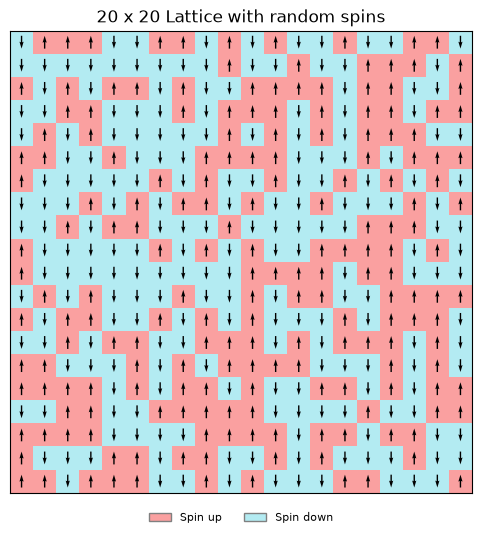

In [5]:
# 1. Create a 20 x 20 lattice with randomly initialized spins of +1 or -1

n = 20

rng = np.random.default_rng()
lattice = rng.choice([-1, 1], size = (n, n)) # choose between -1 or 1 randomly for each element

# 2. Plot the initial spin configuration

# make drawing a lattice a function so i can call it many times

def drawLattice(ax, lattice, title=None):
    colors = ["#B3EBF2", "#FAA0A0"]
    cmap = ListedColormap(colors)
    ax.imshow(lattice, cmap=cmap, vmin=-1, vmax=1, origin='lower', interpolation='nearest')
    y, x = np.indices(lattice.shape)
    ax.quiver(x, y, np.zeros_like(lattice), lattice, pivot='mid', angles='xy')
    ax.set_xticks([]); ax.set_yticks([])
    if title:
        ax.set_title(title)
    legend_handles = [Patch(facecolor=colors[1], edgecolor="gray", label="Spin up"),
                      Patch(facecolor=colors[0], edgecolor="gray", label="Spin down")]
    ax.legend(handles=legend_handles, loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=2, frameon=False, fontsize=8)

fig, ax = plt.subplots(figsize = (6,6))
drawLattice(ax, lattice, f"{n} x {n} Lattice with random spins")
plt.savefig('s1.png')
plt.show()

# turning whatever is above into a function so i can create lattices
def createLattice(dim):
    lattice = rng.choice([-1, 1], size = (dim, dim))
    return lattice

In [6]:
# 3. Write a function to calculate the total energy using:

# consts
J = 1

def totalEnergy(lattice, J = 1):
    # H = -J sum_ij [S_ij (S_i+1, j + S_i, j+1)

    # for S_i+1, j, we can shift i (row) by 1
    # since periodic boundary conditions, i can just put the topmost row to the bottom row (the next neighbor of bottomest row is the topmost row)
    lattice_row_shift = np.roll(lattice, shift = -1, axis = 0)
    
    # do the same for column shift, shift leftest column to the rightest part
    lattice_col_shift = np.roll(lattice, shift = -1, axis = 1)
    
    # total shift term sum
    shift_sum = lattice_row_shift + lattice_col_shift
    
    # note: element wise multiplication
    product = lattice * shift_sum
    
    # sum up all the elements
    H = -J * np.sum(product)
    return H

energy = totalEnergy(lattice, J)

print(f"Energy = {energy}")

Energy = 32


## 2. Implementing the Metropolis Algorithm

In [7]:
# 1. Randomly select a spin S_i,j

# first we have to copy the lattice, in case we need it later
lattice2 = lattice.copy()

rand_i = rng.integers(0,n)
rand_j = rng.integers(0,n)

random_spin = lattice2[rand_i, rand_j]

print("---------------")
print("Selected Spin:")
print(f"Spin_{rand_i, rand_j} = {random_spin}")
print("---------------")

# 2. Flip its orientation
lattice2[rand_i, rand_j] = random_spin * -1

# 3. Calculate the energy change
old_energy = totalEnergy(lattice, J)
new_energy = totalEnergy(lattice2, J)

dH = new_energy - old_energy
print(f"Old energy = {old_energy}")
print(f"New energy = {new_energy}")
print(f"Change in energy = {dH}")
print("---------------")

# code above is for demonstration and debugging purposes, below is the function form so that i can reuse it
def perturb(lattice, hamiltonian, **H_params):
    lattice2 = lattice.copy()

    rand_i = rng.integers(0, lattice.shape[0])
    rand_j = rng.integers(0, lattice.shape[1])

    random_spin = lattice2[rand_i, rand_j]
    lattice2[rand_i, rand_j] = random_spin * -1

    old_energy = hamiltonian(lattice, **H_params)
    new_energy = hamiltonian(lattice2, **H_params)

    dH = new_energy - old_energy

    return dH, lattice2

---------------
Selected Spin:
Spin_(np.int64(19), np.int64(0)) = -1
---------------
Old energy = 32
New energy = 32
Change in energy = 0
---------------


In [10]:
# 4. Accept the flip with probability
# P_accept = min(1, exp(-delta_H/(k_B T)))

# consts:
kB = 1
T = 1

# probability of acceptance from boltzmann distribution
P_accept = min(1, np.exp(-dH/(kB*T)))
# random roll from 0 to 1
roll = rng.random()
print("---------------")
print(f"P = {P_accept}")
print(f"Rolled value = {roll}")
print("---------------")

def willYouAccept(dH, T):

    # probability of acceptance from boltzmann distribution
    P_accept = min(1, np.exp(-dH/(kB*T)))
    # random roll from 0 to 1
    roll = rng.random()
    # if roll within probability then return true, otherwise false
    if roll <= P_accept:
        return True
    else:
        return False    

---------------
P = 1
Rolled value = 0.6097113637061029
---------------


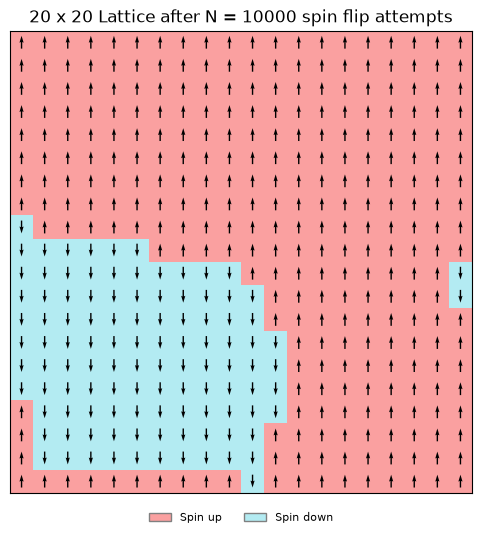

-700


In [11]:
# perform the monte carlo
N = 10000

my_lattice = createLattice(n)

for i in range(N):
    # perturb it
    dH, new_lattice = perturb(my_lattice, totalEnergy, J = J)
    # check if it will accept the perturbation
    # if accept: new_lattice is the my_lattice
    # if not: my_lattice remains
    if willYouAccept(dH, T):
        my_lattice = new_lattice

# plot the result:

fig, ax = plt.subplots(figsize = (6,6))
drawLattice(ax, my_lattice, f"{n} x {n} Lattice after N = {N} spin flip attempts")
plt.savefig('s2.png')
plt.show()

# print total energy
print(totalEnergy(my_lattice, 1))

## 3. Investigating Spontaneous Magnetization

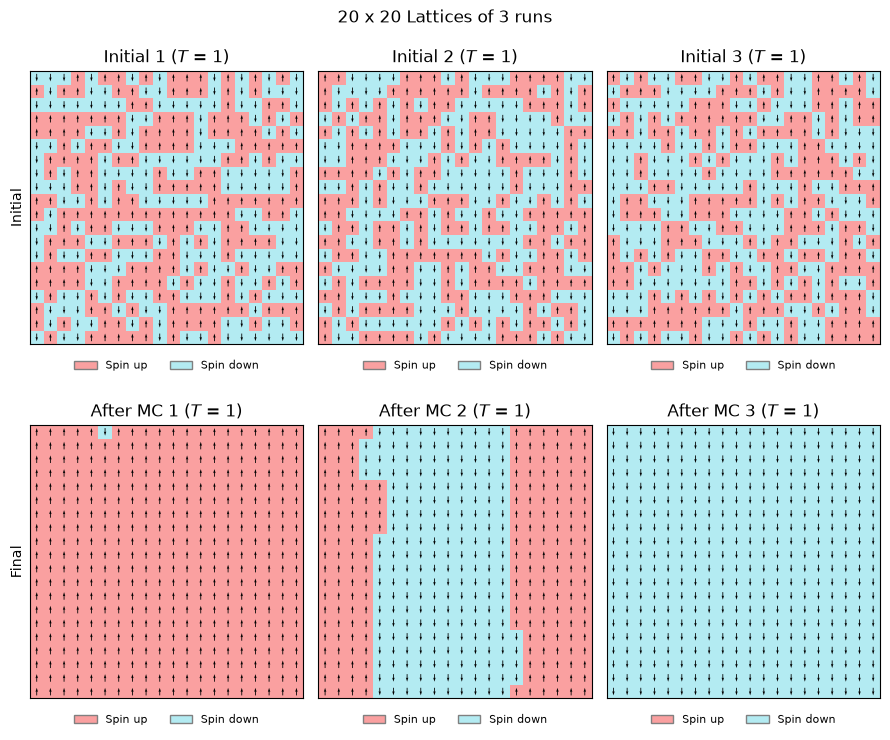

In [42]:
# 1. Run the simulation for 10e4 - 10e6 attempted spin flips, you decide what's appropriate
# 2. Record the magnetization per spin and total energy throughout the simulation;

#-----------------------------------
# sandbox for recording magnetization

# to record total magnetization we calculate it as M = sum of all elements
# to record average magnetization per spin it is m = M/N^2
# to be efficient we can just record M as an array and then calculate m from there

# create a recording array for M
#-----------------------------------

def monteCarlo(my_lattice, hamiltonian, T, N = 1e5, **H_params):

    # storage arrays:
    M = [] # for total magnetization

    N = int(N)
    n = my_lattice.shape[0]

    for i in range(N):
        # perturb it
        dH, new_lattice = perturb(my_lattice, hamiltonian, **H_params)
        # check if it will accept the perturbation
        # if accept: new_lattice is the my_lattice
        # if not: my_lattice remains
        if willYouAccept(dH, T):
            my_lattice = new_lattice

        M.append(np.sum(my_lattice)) # get the total magnetization for each step

    # then we can calculate the average magnetization per spin
    M = np.array(M)
    m = M/(n**2)

    return my_lattice, M, m

def runSimulations(T_runs, hamiltonian, **H_params):
    initial_lattices = [createLattice(n) for _ in T_runs]

    final_lattices, M_runs, m_runs = [], [], []
    for lat, T in zip(initial_lattices, T_runs):
        final, M, m = monteCarlo(lat, hamiltonian, T, **H_params)
        final_lattices.append(final)
        M_runs.append(M)
        m_runs.append(m)

    return initial_lattices, final_lattices, M_runs, m_runs

def plotRunLattices(initial_lattices, final_lattices, T_runs):
    n_runs = len(T_runs)
    fig, axs = plt.subplots(2, n_runs, figsize=(3 * n_runs, 7.5))
    for k in range(n_runs):
        drawLattice(axs[0, k], initial_lattices[k], f"Initial {k+1} ($T$ = {T_runs[k]:g})")
        drawLattice(axs[1, k], final_lattices[k], f"After MC {k+1} ($T$ = {T_runs[k]:g})")
    axs[0, 0].set_ylabel("Initial")
    axs[1, 0].set_ylabel("Final")
    fig.suptitle(f"{n} x {n} Lattices of {n_runs} runs")
    fig.tight_layout(h_pad = 2)

n_runs = 3
T_runs = [T] * n_runs

initial_lattices, final_lattices, M_runs, m_runs = runSimulations(T_runs, totalEnergy, J = J)

plotRunLattices(initial_lattices, final_lattices, T_runs)
plt.savefig("s3p1.png")
plt.show()

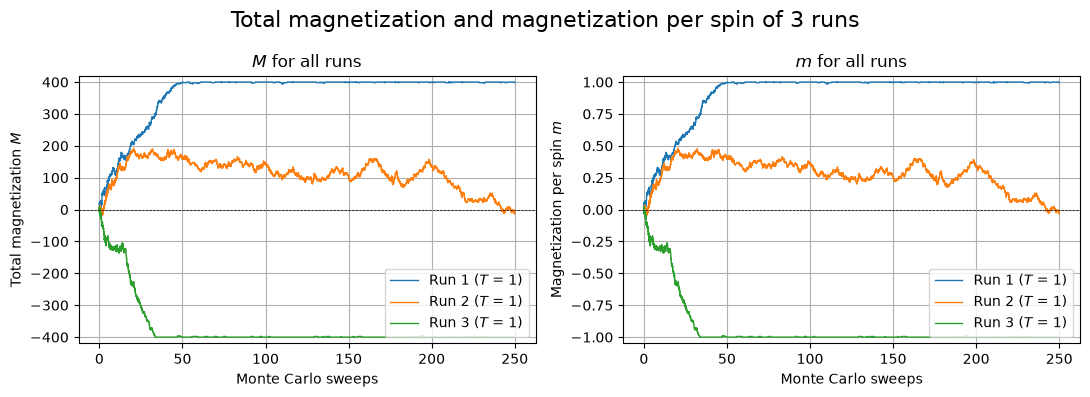

In [43]:
def plotRunMagnetization(M_runs, m_runs, T_runs):
    fig2, (ax_M, ax_m) = plt.subplots(1, 2, figsize=(11, 4))

    # M and m were recorded after every attempted flip
    # n^2 lattice, so n^2 attempts is one "sweep"
    sweeps = np.arange(1, len(M_runs[0]) + 1) / n**2

    for k in range(len(M_runs)):
        ax_M.plot(sweeps, M_runs[k], lw=1, label=f"Run {k+1} ($T$ = {T_runs[k]:g})")
        ax_m.plot(sweeps, m_runs[k], lw=1, label=f"Run {k+1} ($T$ = {T_runs[k]:g})")

    ax_M.set_xlabel("Monte Carlo sweeps")
    ax_M.set_ylabel("Total magnetization $M$")
    ax_M.set_title("$M$ for all runs")
    ax_M.set_ylim(-n**2 * 1.05, n**2 * 1.05)

    ax_m.set_xlabel("Monte Carlo sweeps")
    ax_m.set_ylabel("Magnetization per spin $m$")
    ax_m.set_title("$m$ for all runs")
    ax_m.set_ylim(-1.05, 1.05)

    for ax in (ax_M, ax_m):
        ax.axhline(0, color="black", lw=0.5, ls="--")
        ax.legend()
        ax.grid()

    fig2.suptitle(f"Total magnetization and magnetization per spin of {len(M_runs)} runs", fontsize = 16)
    fig2.tight_layout()

plotRunMagnetization(M_runs, m_runs, T_runs)
plt.savefig('s3p2.png')
plt.show()

## 4. Introducing an External Magnetic Field

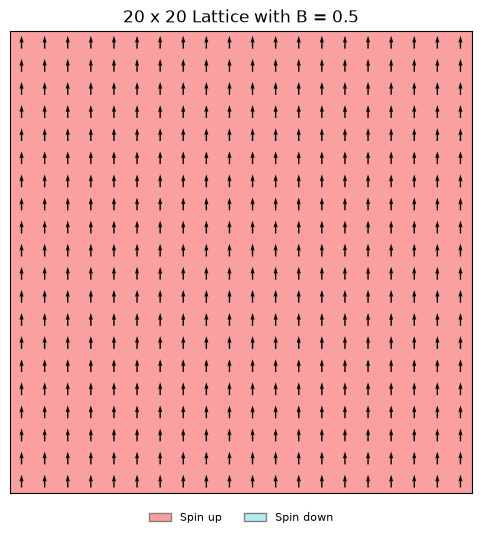

In [27]:
# Modify the Hamiltonian to include a uniform external magnetic field

# 1. Update the energy calculation and Metropolis algorithm

# consts
B = 0.5

def modifiedHamiltonian(lattice, J, B):
    # H = -J sum_ij [S_ij (S_i+1, j + S_i, j+1)

    # for S_i+1, j, we can shift i (row) by 1
    # since periodic boundary conditions, i can just put the topmost row to the bottom row (the next neighbor of bottomest row is the topmost row)
    lattice_row_shift = np.roll(lattice, shift = -1, axis = 0)
    
    # do the same for column shift, shift leftest column to the rightest part
    lattice_col_shift = np.roll(lattice, shift = -1, axis = 1)
    
    # total shift term sum
    shift_sum = lattice_row_shift + lattice_col_shift
    
    # note: element wise multiplication
    product = lattice * shift_sum
    
    # sum up all the elements
    H_term = -J * np.sum(product)

    # Now for the B term
    B_term = B * np.sum(lattice)

    return H_term - B_term

# simulating
my_lattice = createLattice(n)
my_lattice, M, m = monteCarlo(my_lattice, modifiedHamiltonian, T, J = J, B = B)

fig, ax = plt.subplots(figsize = (6,6))
drawLattice(ax, my_lattice, f"{n} x {n} Lattice with B = {B}")
plt.savefig('s4p1.png')
plt.show()

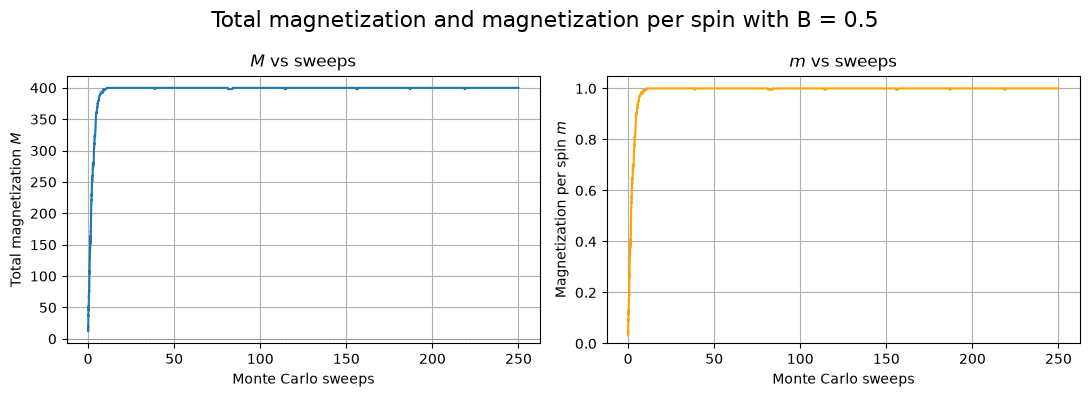

In [28]:
def plotFieldMagnetization(M, m, B):
    sweeps = np.arange(1, len(M) + 1) / n**2 

    fig, axs = plt.subplots(1, 2, figsize=(11, 4))

    axs[0].plot(sweeps, M)
    axs[0].set_xlabel("Monte Carlo sweeps")
    axs[0].set_ylabel("Total magnetization $M$")
    axs[0].set_title("$M$ vs sweeps")

    axs[1].plot(sweeps, m, color = 'orange')
    axs[1].set_xlabel("Monte Carlo sweeps")
    axs[1].set_ylabel("Magnetization per spin $m$")
    axs[1].set_title("$m$ vs sweeps")
    axs[1].set_ylim(0, 1.05)

    for ax in axs:
        ax.axhline(0, color="gray", lw=0.5, ls="--")
        ax.grid()
        
    fig.suptitle(f"Total magnetization and magnetization per spin with B = {B}", fontsize = 16)
    fig.tight_layout()

plotFieldMagnetization(M, m, B)
plt.savefig('s4p2.png')
plt.show()

## 5. Critical Temperature

In [29]:
# Previously, T = 1, Redo Sections 2, 3, and 4, by selecting a temperature above Tc

# consts
T_new = 5 * J / kB

### Section 2 Retry

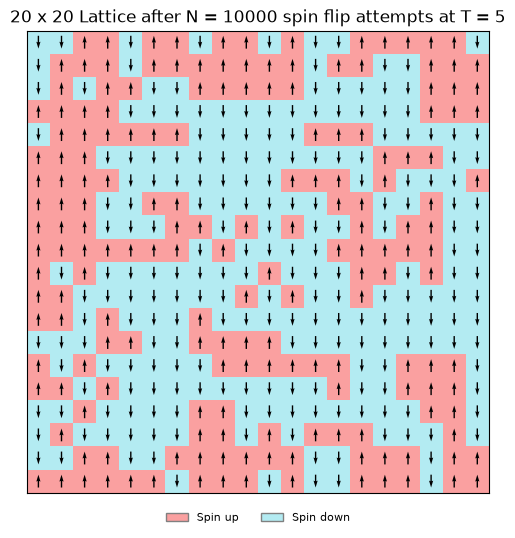

In [30]:
# perform the monte carlo
N = 10000

my_lattice = createLattice(n)
my_lattice, M, m = monteCarlo(my_lattice, totalEnergy, T_new, N, J = J)

# plot the result:

fig, ax = plt.subplots(figsize = (6,6))
drawLattice(ax, my_lattice, f"{n} x {n} Lattice after N = {N} spin flip attempts at T = 5")
plt.savefig('s5s2.png')

### Section 3 Retry

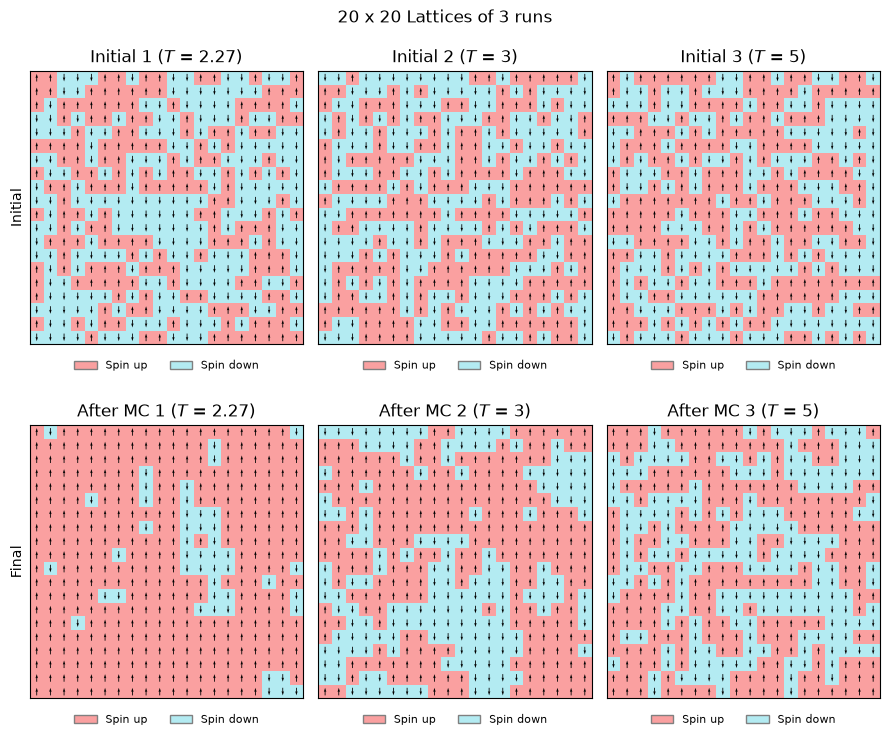

In [31]:
# 1. Run the simulation for 10e4 - 10e6 attempted spin flips, you decide what's appropriate
# 2. Record the magnetization per spin and total energy throughout the simulation;

#-----------------------------------
# sandbox for recording magnetization

# to record total magnetization we calculate it as M = sum of all elements
# to record average magnetization per spin it is m = M/N^2
# to be efficient we can just record M as an array and then calculate m from there

# create a recording array for M
#-----------------------------------

T_runs = np.array([2.27, 3, 5]) * J / kB

initial_lattices, final_lattices, M_runs, m_runs = runSimulations(T_runs, totalEnergy, J = J)

plotRunLattices(initial_lattices, final_lattices, T_runs)
plt.savefig("s5s3p1.png")
plt.show()

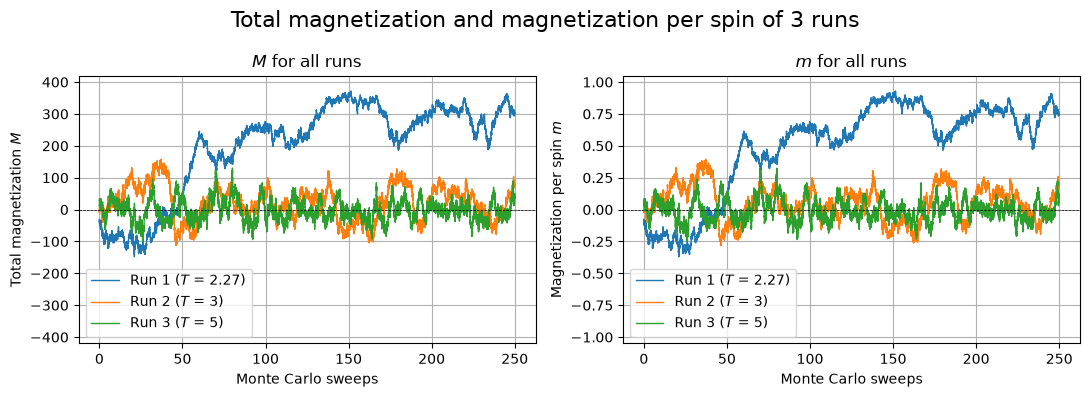

In [32]:
plotRunMagnetization(M_runs, m_runs, T_runs)
plt.savefig('s5s3p2.png')
plt.show()

### Section 4 Retry

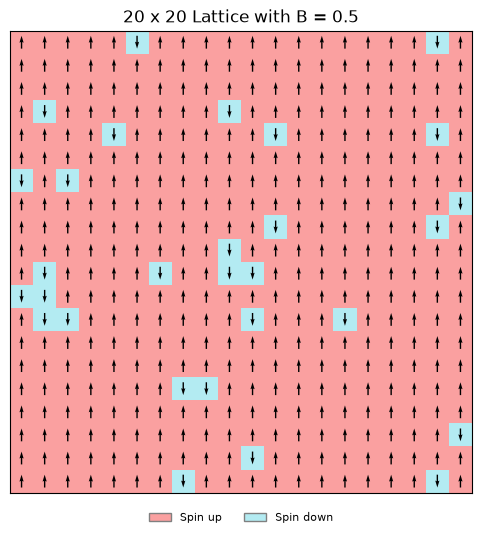

In [33]:
# Modify the Hamiltonian to include a uniform external magnetic field

# 1. Update the energy calculation and Metropolis algorithm

# consts
T_new = 3 * J / kB

# simulating
my_lattice = createLattice(n)
my_lattice, M, m = monteCarlo(my_lattice, modifiedHamiltonian, T_new, J = J, B = B)

fig, ax = plt.subplots(figsize = (6,6))
drawLattice(ax, my_lattice, f"{n} x {n} Lattice with B = {B}")
plt.savefig('s5s4p1.png')
plt.show()

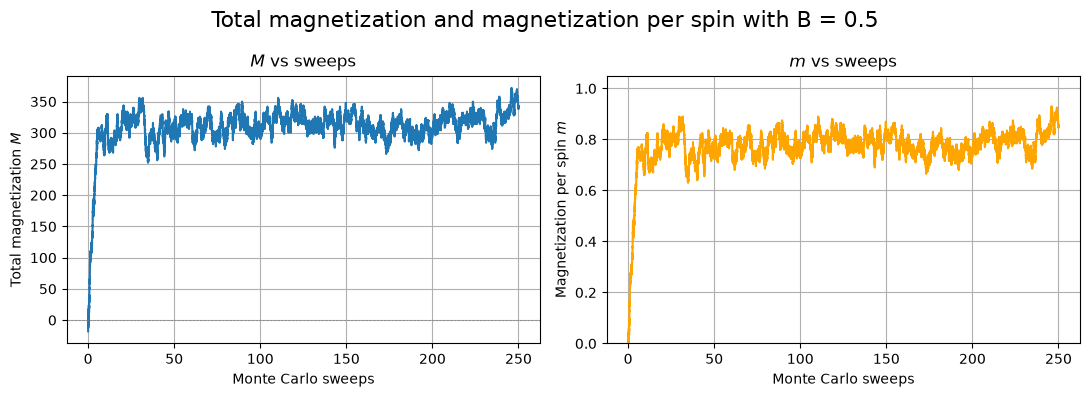

In [34]:
plotFieldMagnetization(M, m, B)
plt.savefig('s5s4s2.png')
plt.show()

In [44]:
def monteCarloME(my_lattice, hamiltonian, T, N = 1e5, **H_params):
    N = int(N)
    n = my_lattice.shape[0]
    E_now = hamiltonian(my_lattice, **H_params)
    M = np.empty(N)
    E = np.empty(N)

    for i in range(N):
        dH, new_lattice = perturb(my_lattice, hamiltonian, **H_params)
        if willYouAccept(dH, T):
            my_lattice = new_lattice
            E_now += dH
        M[i] = np.sum(my_lattice)
        E[i] = E_now

    return my_lattice, M / n**2, E

def runSimulationsME(initial_lattices, T_runs, hamiltonian, N = 1e5, **H_params):
    final_lattices, m_runs, E_runs = [], [], []
    for lat, T in zip(initial_lattices, T_runs):
        final, m, E = monteCarloME(lat, hamiltonian, T, N, **H_params)
        final_lattices.append(final)
        m_runs.append(m)
        E_runs.append(E)

    return final_lattices, m_runs, E_runs

def plotMagnetizationEnergy(ax_m, ax_E, m_runs, E_runs, T_runs, title):
    sweeps = np.arange(1, len(m_runs[0]) + 1) / n**2

    for k in range(len(m_runs)):
        label = f"Run {k+1} ($T$ = {T_runs[k]:g})"
        ax_m.plot(sweeps, m_runs[k], lw = 1, label = label)
        ax_E.plot(sweeps, E_runs[k], lw = 1, label = label)

    ax_m.set_title(title)
    ax_m.set_ylabel("Magnetization per spin $m$")
    ax_m.set_ylim(-1.05, 1.05)
    ax_m.axhline(0, color = "black", lw = 0.5, ls = "--")
    ax_E.set_ylabel("Total energy $H$")

    for ax in (ax_m, ax_E):
        ax.set_xlabel("Monte Carlo sweeps")
        ax.legend()
        ax.grid()

N_flips = 100000
T_below = [1, 1, 1]
T_above = [2.27, 3, 5]

initial_lattices = [createLattice(n) for _ in range(3)]

final_below, m_below, E_below = runSimulationsME(initial_lattices, T_below, totalEnergy, N_flips, J = J)
final_above, m_above, E_above = runSimulationsME(initial_lattices, T_above, totalEnergy, N_flips, J = J)

_, mB_below, EB_below = runSimulationsME(initial_lattices[:1], [1], modifiedHamiltonian, N_flips, J = J, B = B)
_, mB_above, EB_above = runSimulationsME(initial_lattices[:1], [3], modifiedHamiltonian, N_flips, J = J, B = B)

## for the sake of report figures

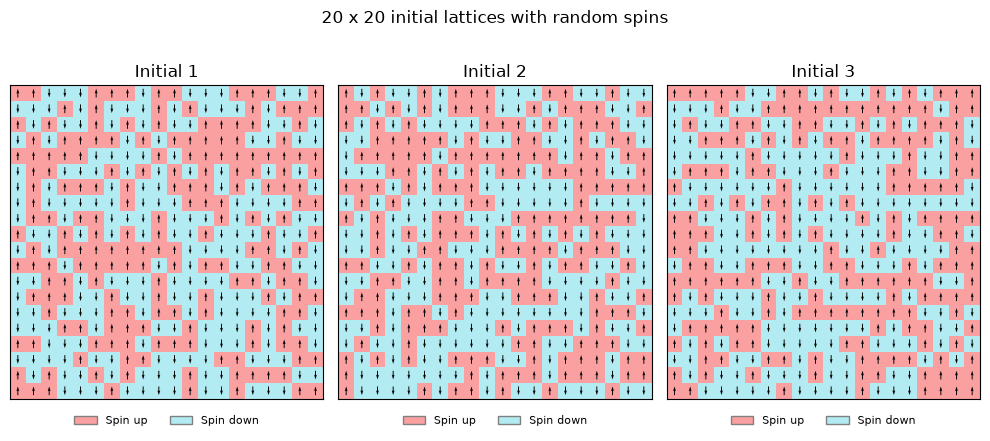

In [45]:
fig, axs = plt.subplots(1, 3, figsize = (10, 4.5))
for k in range(3):
    drawLattice(axs[k], initial_lattices[k], f"Initial {k+1}")
fig.suptitle(f"{n} x {n} initial lattices with random spins")
fig.tight_layout()
plt.savefig('report_fig1.png')
plt.show()

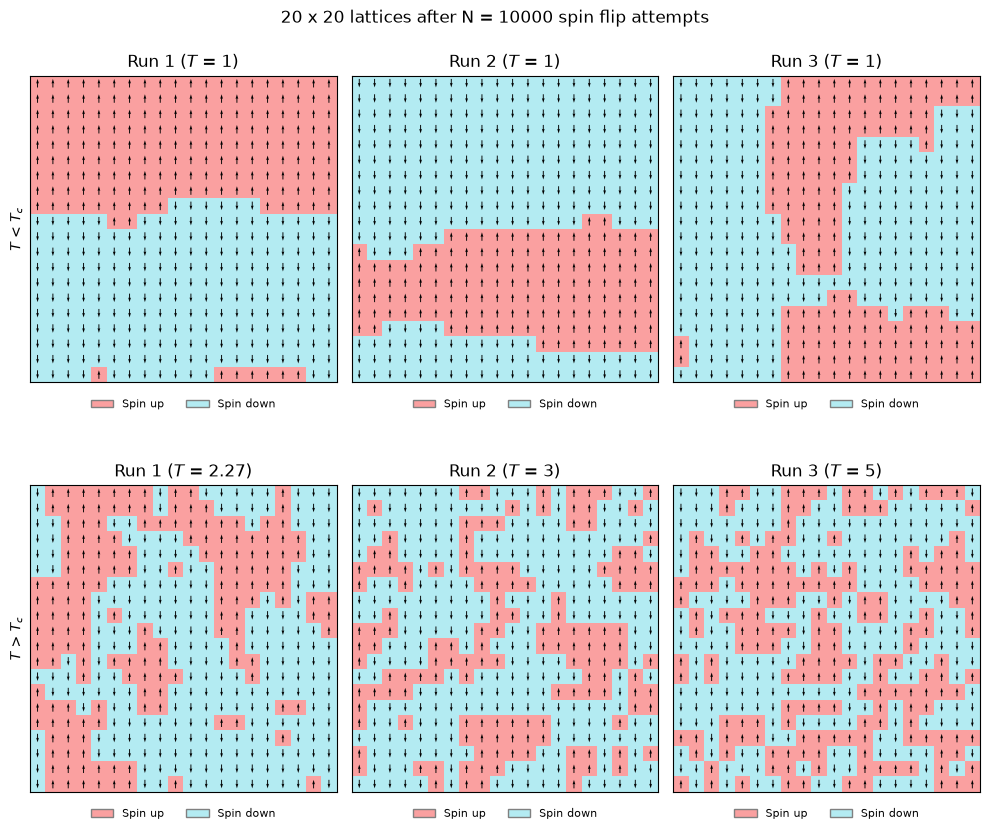

In [37]:
fig, axs = plt.subplots(2, 3, figsize = (10, 8.5))
for k in range(3):
    drawLattice(axs[0, k], final_below[k], f"Run {k+1} ($T$ = {T_below[k]:g})")
    drawLattice(axs[1, k], final_above[k], f"Run {k+1} ($T$ = {T_above[k]:g})")
axs[0, 0].set_ylabel("$T$ < $T_c$")
axs[1, 0].set_ylabel("$T$ > $T_c$")
fig.suptitle(f"{n} x {n} lattices after N = {N_flips} spin flip attempts")
fig.tight_layout(h_pad = 3.5)
plt.savefig('report_fig2.png')
plt.show()

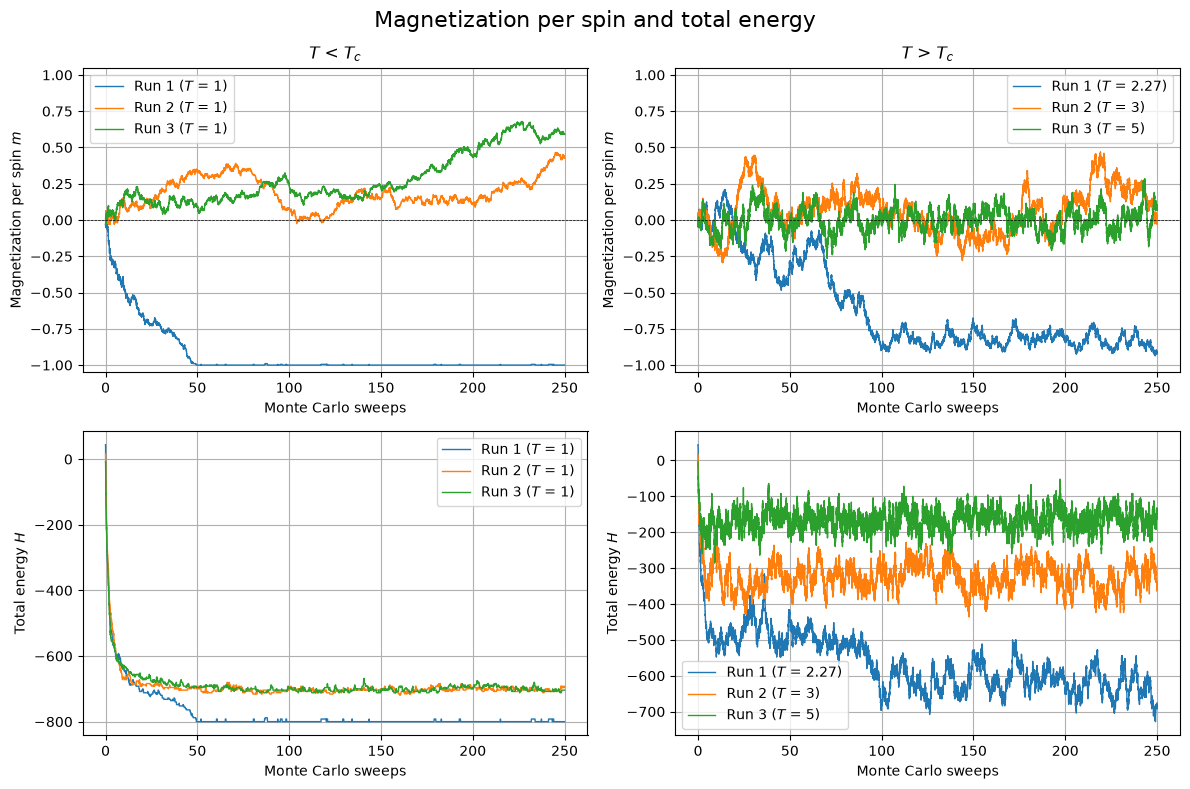

In [46]:
fig, axs = plt.subplots(2, 2, figsize = (12, 8))
plotMagnetizationEnergy(axs[0, 0], axs[1, 0], m_below, E_below, T_below, "$T$ < $T_c$")
plotMagnetizationEnergy(axs[0, 1], axs[1, 1], m_above, E_above, T_above, "$T$ > $T_c$")
fig.suptitle("Magnetization per spin and total energy", fontsize = 16)
fig.tight_layout()
plt.savefig('report_fig3.png')
plt.show()

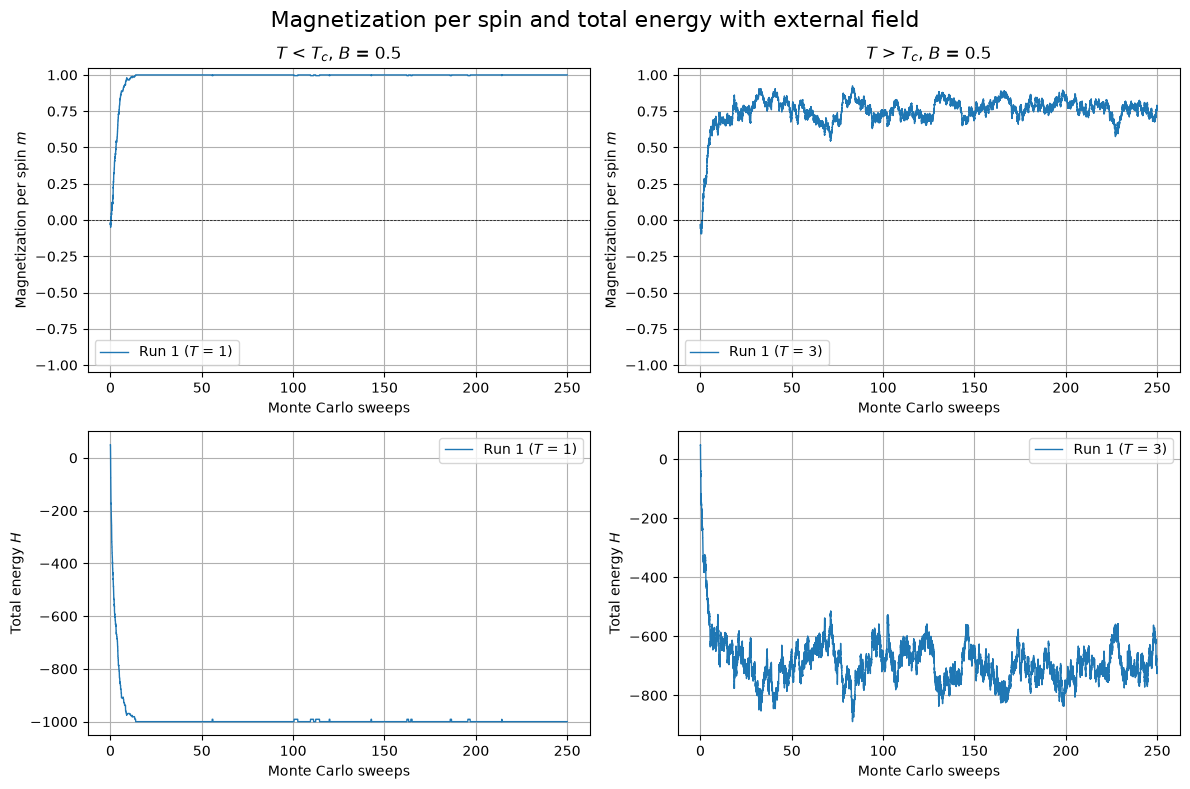

In [47]:
fig, axs = plt.subplots(2, 2, figsize = (12, 8))
plotMagnetizationEnergy(axs[0, 0], axs[1, 0], mB_below, EB_below, [1], f"$T$ < $T_c$, $B$ = {B}")
plotMagnetizationEnergy(axs[0, 1], axs[1, 1], mB_above, EB_above, [3], f"$T$ > $T_c$, $B$ = {B}")
fig.suptitle("Magnetization per spin and total energy with external field", fontsize = 16)
fig.tight_layout()
plt.savefig('report_fig4.png')
plt.show()